<a href="https://colab.research.google.com/github/xlasergaming/M-c-Ho-ng-Duy-/blob/main/week1/week_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dongthethang2k15kkk/15-weeks-of-military-training/blob/main/week1/week_1.ipynb)

# Tuần 1 — Nền tảng & Cú pháp cơ bản

![Kết quả cuối tuần 1](https://raw.githubusercontent.com/dongthethang2k15kkk/15-weeks-of-military-training/main/assets/ket_qua_tuan1.png)

Cuối tuần bạn sẽ tự vẽ ra hình này từ dữ liệu của một chuyến xe.

**Mục tiêu sau tuần này, bạn phải làm được:**

1. Khai báo biến đúng quy ước và phân biệt 4 kiểu dữ liệu cơ bản.
2. Dùng thành thạo toán tử số học và định dạng chuỗi bằng f-string.
3. Viết được logic ra quyết định bằng `if / elif / else`.
4. Gói một khối lệnh thành hàm bằng `def` và `return`, gọi lại với nhiều đầu vào.
5. Lặp lại một việc bằng `for` và `while`.
6. Đọc và xử lý file log cảm biến (CSV, NMEA) của một chuyến xe.

**Quy tắc:** không sửa nội dung các ô kiểm tra. Chỉ viết code vào chỗ có `# TODO`
hoặc chỗ được đánh dấu là chỗ viết của bạn.

In [508]:
# Ô thiết lập - chạy đầu tiên, mỗi lần mở notebook.
import os
import sys
import urllib.request

REPO_RAW = "https://raw.githubusercontent.com/dongthethang2k15kkk/15-weeks-of-military-training/main"

# File của tuần này. Chỉ tải file chưa có trên máy.
FILE_TESTS = ("runner.py", "test_week1.py", "tien_ich_du_lieu.py")
FILE_DATA = ("khoang_cach_truoc.csv", "gps.nmea", "obd.csv", "imu.csv")

# Mở notebook từ thư mục week1/ trên máy: lùi ra thư mục gốc, nơi có sẵn tests/.
if not os.path.isdir("tests") and os.path.isdir(os.path.join("..", "tests")):
    os.chdir("..")

for thu_muc, danh_sach in (("tests", FILE_TESTS), ("data", FILE_DATA)):
    os.makedirs(thu_muc, exist_ok=True)
    for ten_file in danh_sach:
        duong_dan = os.path.join(thu_muc, ten_file)
        if not os.path.isfile(duong_dan):
            urllib.request.urlretrieve(f"{REPO_RAW}/{thu_muc}/{ten_file}", duong_dan)
open(os.path.join("tests", "__init__.py"), "a").close()

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from tests.test_week1 import (
    kiem_tra_1_1,
    kiem_tra_1_2,
    kiem_tra_1_3,
    kiem_tra_2_1,
    kiem_tra_2_2,
    kiem_tra_2_3,
    kiem_tra_2_4,
    kiem_tra_2_5,
    kiem_tra_3_1,
    kiem_tra_3_2,
    kiem_tra_3_3,
    kiem_tra_4_1,
    kiem_tra_4_2,
    kiem_tra_4_3,
    kiem_tra_4_4,
    kiem_tra_5_1,
    kiem_tra_5_2,
    kiem_tra_5_3,
    kiem_tra_5_4,
    kiem_tra_5_5,
    kiem_tra_du_an,
    kiem_tra_lab,
)

print("Moi truong san sang. Phien ban Python:", sys.version.split()[0])

Moi truong san sang. Phien ban Python: 3.13.16


---
## Cách làm bài và chấm bài

Mỗi bài tập gồm hai ô đi liền nhau: ô bạn viết code, và ô kiểm tra ngay dưới nó.
Ô kiểm tra đọc các biến hoặc hàm mà ô trên tạo ra, nên **tên phải khớp từng chữ**.

Chạy thử một lượt với bài mẫu dưới đây trước khi vào bài thật.

Đề: gán biến `vi_du_tong` bằng tổng của `3` và `4`.

In [509]:
vi_du_tong = 3 + 4  # sửa dòng này: thay None bằng 3 + 4

Ô ngay trên là chỗ bạn viết. Sửa `None` thành `3 + 4`, rồi bấm Shift+Enter để chạy
ô đó. Sau đó bấm Shift+Enter tiếp ở ô dưới đây để chấm.

In [510]:
if vi_du_tong == 7:
    print("PASS - ban da lam dung, sang Bai 1 duoc roi")
else:
    print(f"FAIL - mong doi 7, thuc te {vi_du_tong}")

PASS - ban da lam dung, sang Bai 1 duoc roi


Ba điều rút ra, áp dụng cho mọi bài trong khoá:

1. Sửa xong ô code phải **chạy lại chính ô đó** rồi mới chạy ô kiểm tra. Bỏ qua
   bước này thì ô kiểm tra vẫn đọc giá trị cũ, và bạn sẽ thấy FAIL dù đã sửa đúng.
2. Chưa làm gì mà chạy ô kiểm tra thì nó báo FAIL kèm dòng "thực tế: None". Đó là
   trạng thái bình thường lúc mới mở notebook.
3. Dòng "mong đợi" trong báo lỗi cho biết đáp án đúng phải trông ra sao. So nó với
   dòng "thực tế" để biết lệch ở đâu.

Chạy lại cả notebook từ đầu bằng `Runtime > Restart and run all` nếu thấy kết quả
lộn xộn không giải thích được.

---
## Bài 1 — Biến và kiểu dữ liệu

#### 📖 Cú pháp

| Cú pháp | Nghĩa | Ví dụ |
|---|---|---|
| `ten_bien = gia_tri` | gán giá trị cho biến (biến là một cái tên gắn với một giá trị trong bộ nhớ, kiểu được suy ra từ giá trị, không cần khai báo trước) | `toc_do_dong_co = 120` |
| `int` | kiểu số nguyên | `toc_do_dong_co = 120` (vòng/phút) |
| `float` | kiểu số thực | `dien_ap_pin = 11.5` (V) |
| `str` | kiểu chuỗi ký tự, đặt trong dấu nháy | `trang_thai_he_thong = "Dang chay"` |
| `bool` | kiểu đúng/sai, chỉ có `True` và `False` | `cam_bien_hoat_dong = True` |
| `snake_case` | quy ước đặt tên biến (PEP 8): viết thường, các từ nối bằng dấu gạch dưới | `so_lan_doc_cam_bien` |
| `VIET_HOA` | quy ước đặt tên hằng số: viết hoa toàn bộ | `TOC_DO_TOI_DA = 150` |
| `print(x)` | in giá trị `x` ra màn hình | `print(11.5)` → `11.5` |
| `type(x)` | cho biết kiểu dữ liệu của `x` | `type(11.5)` → `<class 'float'>` |
| `int(x)` | ép `x` sang số nguyên | `int("10")` → `10`, `int(10.9)` → `10` |
| `float(x)` | ép `x` sang số thực | `float("10.5")` → `10.5` |
| `round(x)` HOẶC `round(x, n)` | làm tròn `x` đến `n` chữ số sau dấu phẩy | `round(10.9)` → `11`, `round(10.9, 0)` → `11.0` |
| `a + b` | cộng hai số, hoặc nối hai chuỗi | `10 + 5` → `15`, `"10" + "5"` → `"105"` |
| `dong.split(",")[i]` | cắt dòng chữ theo dấu phẩy, lấy cột thứ `i` (đếm từ 0) | `"1.5,302.0".split(",")[1]` → `"302.0"` |
| `dong.strip()` | bỏ khoảng trắng và ký tự xuống dòng ở hai đầu chuỗi | `"5\n".strip()` → `"5"` |

#### ⚠️ Lỗi hay gặp

- `int("10.5")` báo `ValueError` vì `int()` không đọc được dấu chấm. Ép qua `float()`
  trước: `int(float("10.5"))`.
- Chuỗi gõ từ bàn phím hoặc cắt từ một dòng chữ luôn có kiểu `str`, phải ép kiểu
  trước khi tính: `float("302.0")`, `int(input("So xe: "))`.
- `int(10.9)` cho `10` vì **cắt bỏ phần thập phân** (truncation), còn `round(10.9)`
  cho `11`.
- `int("10") + int("5")` là **phép cộng đại số**, cho `15`. `int("10" + "5")` là
  **nối chuỗi** `"10"` với `"5"` thành `"105"` rồi mới ép kiểu, cho `105`.
- Dùng biến chưa gán thì Python báo `NameError`.
- Nên đặt tên theo nội dung: `toc_do_xe`, `so_lan_doc_cam_bien`, không đặt kiểu `x`,
  `a1`.

In [511]:
# 💻 Ví dụ: bốn kiểu dữ liệu và hằng số
toc_do_dong_co = 120               # int
dien_ap_pin = 11.5                 # float
trang_thai_he_thong = "Dang chay"  # str
cam_bien_hoat_dong = True          # bool

TOC_DO_TOI_DA = 150                # hằng số: viết HOA

print(toc_do_dong_co, type(toc_do_dong_co))     # lệnh type() để check kiểu dữ liệu
print(dien_ap_pin, type(dien_ap_pin))
print(trang_thai_he_thong, type(trang_thai_he_thong))
print(cam_bien_hoat_dong, type(cam_bien_hoat_dong))

120 <class 'int'>
11.5 <class 'float'>
Dang chay <class 'str'>
True <class 'bool'>


`"10"` và `10` là hai thứ khác nhau, `int()` và `float()` chỉ ép được chuỗi đúng
định dạng số.

In [512]:
# 💻 Ví dụ: ép kiểu chuỗi sang số
print(int("10"))               # 10 - toàn chữ số, ép được
# print(int("10.5"))           # Bỏ dấu # để thấy lỗi ValueError
print(int(float("10.5")))      # 10 - ép qua float() trước rồi mới int() sau

10
10


Muốn ra số nguyên từ chuỗi có dấu chấm thì ép qua `float()` trước rồi mới `int()`.

In [513]:
# 💻 Ví dụ: int() và round()
print(int(10.9))     # 10 - cắt bỏ phần thập phân
print(round(10.9))   # 11 - làm tròn theo quy tắc toán học

10
11


Hai hàm cho hai kết quả khác nhau.

In [514]:
# 💻 Ví dụ: dùng biến chưa gán
# print(bien_chua_gan)   # Bỏ dấu # để thấy lỗi NameError

Biến phải được gán trước khi dùng.

In [515]:
# 💻 Ví dụ: dấu + với số và với chuỗi
print(int("10") + int("5"))   # 15 - ép hai chuỗi thành số rồi mới cộng
print(int("10" + "5"))        # 105 - nối chuỗi "10" với "5" trước rồi mới ép

15
105


Cùng các ký tự `1`, `0`, `5` nhưng thứ tự thao tác khác nhau cho hai kết quả khác
nhau.

In [516]:
# 💻 Ví dụ: bool và số nguyên
print(type(True), True == 1)   # <class 'bool'> True

<class 'bool'> True


`type(True)` trả về `bool`, không phải `int`, dù `True == 1` vẫn đúng.

### 🎯 Bài tập 1.1 — Trung bình lần đọc cảm biến

Cảm biến khoảng cách bị nhiễu nên đọc 3 lần liên tiếp cho một cảm biến. Có hai
cảm biến. Với mỗi cảm biến, gán biến `tb_doc_*` bằng trung bình cộng ba lần đọc.

In [517]:
doc_1_1, doc_1_2, doc_1_3 = 8, 9, 10
doc_2_1, doc_2_2, doc_2_3 = 7.5, 6, 8

tb_doc_1 = (8 + 9 + 10) / 3  # TODO: trung bình cộng của doc_1_1, doc_1_2, doc_1_3
tb_doc_2 = (7.5 + 6 + 8) /3  # TODO: trung bình cộng của doc_2_1, doc_2_2, doc_2_3

In [518]:
kiem_tra_1_1(tb_doc_1, tb_doc_2)


Bài 1.1 - Trung bình lần đọc cảm biến
  PASS  test 1: tb_doc_1 (cảm biến 1: 8, 9, 10) -> 9.0
  PASS  test 2: tb_doc_2 (cảm biến 2: 7.5, 6, 8) -> 7.166666666666667
  Kết quả: 2/2 — Đạt!


True

### 🎯 Bài tập 1.2 — Ép kiểu dữ liệu

Cho chuỗi `gia_tri_tho_2`. Gán `noi_chuoi` bằng cách nối nó với chuỗi `"5"`, và
gán `tong_so` bằng cách ép nó sang số nguyên rồi cộng thêm `5`. Xem lại ô ví dụ
ngay phía trên nếu chưa rõ khác nhau ở đâu.

In [519]:
gia_tri_tho_2 = "20"

noi_chuoi = gia_tri_tho_2 + "5"  # TODO: gia_tri_tho_2 nối với "5"
tong_so = int(gia_tri_tho_2) + 5    # TODO: ép gia_tri_tho_2 sang int rồi cộng 5

In [520]:
kiem_tra_1_2(noi_chuoi, tong_so)


Bài 1.2 - Ép kiểu dữ liệu
  PASS  test 1: noi_chuoi (gia_tri_tho_2 + "5") -> '205'
  PASS  test 2: tong_so (int(gia_tri_tho_2) + 5) -> 25
  Kết quả: 2/2 — Đạt!


True

### 📡 Bài tập 1.3 — Một dòng LiDAR

Dòng `dong_kc` lấy từ `data/khoang_cach_truoc.csv`, ghi của cảm biến LiDAR 1D gắn
phía trước xe, tại giây 113.00 của chuyến. Hai cột là thời gian (giây) và khoảng
cách tới vật phía trước (cm).

Gán `thoi_gian_mau` (float, giây) và `khoang_cach_m` (float, mét).

Ví dụ: dòng `"113.05,694.5\n"` cho `thoi_gian_mau = 113.05`, `khoang_cach_m = 6.945`.

In [521]:
# 💻 Ví dụ: lấy một cột từ dòng log
dong_1, dong_2 = "5.00,1200.0\n", "113.05,694.5\n"
print(float(dong_1.strip().split(",")[1]) / 100)   # strip() bỏ "\n", split(",") cắt theo dấu phẩy, [1] lấy cột 1
print(float(dong_2.strip().split(",")[1]) / 100)

12.0
6.945


In [522]:
dong_kc = "113.00,735.6\n"

thoi_gian_mau = float(dong_kc.strip().split(",")[0])  # TODO: float, giây
khoang_cach_m = float(dong_kc.strip().split(",")[1]) / 100  # TODO: float, mét

In [523]:
kiem_tra_1_3(thoi_gian_mau, khoang_cach_m)


Bài 1.3 - Một dòng LiDAR
  PASS  test 1: thoi_gian_mau ("113.00,735.6") -> 113.0
  PASS  test 2: khoang_cach_m (735.6 cm đổi ra mét) -> 7.356
  Kết quả: 2/2 — Đạt!


True

---
## Bài 2 — Toán tử, chuỗi và ép kiểu

#### 📖 Cú pháp

| Cú pháp | Nghĩa | Ví dụ |
|---|---|---|
| `+`, `-`, `*` | cộng, trừ, nhân | `7 * 3` → `21` |
| `/` | chia, luôn trả về `float` | `10 / 2` → `5.0` |
| `//` | chia lấy phần nguyên | `17 // 5` → `3` |
| `%` | chia lấy phần dư, kết quả luôn từ `0` đến `b - 1`, hay dùng để chia chu kỳ, đổi đơn vị | `17 % 5` → `2`, `gio % 24` luôn ra giờ từ 0 đến 23 |
| `**` | lũy thừa (mũ) | `2 ** 3` → `8` |
| `a == (a // b) * b + a % b` | quan hệ luôn đúng giữa `//` và `%` khi `a`, `b` là số nguyên dương: `//` cho thương, `%` cho số dư | `17 == 3 * 5 + 2` |
| `f"...{x}..."` | f-string: đặt `f` trước dấu nháy, nhúng biểu thức vào giữa cặp ngoặc nhọn `{}` | `f"{3 * 4} km"` → `"12 km"` |
| `{x:.2f}` | trong f-string, hiển thị `x` với 2 chữ số sau dấu phẩy, giá trị của `x` giữ nguyên | `f"{7.1666:.2f}"` → `"7.17"` |
| `round(x, n)` | làm tròn giá trị `x` đến `n` chữ số sau dấu phẩy, giá trị đổi thật | `round(7.1666, 2)` → `7.17` |
| `str(x)` | ép `x` sang chuỗi | `str(50)` → `"50"` |
| `input("lời nhắc")` | đọc chữ gõ từ bàn phím, luôn trả về `str` | `int(input("So xe: "))` |

#### ⚠️ Lỗi hay gặp

- Ghép chuỗi với số bằng `+` báo `TypeError`, phải gọi `str()` cho từng số:
  `"Toc do: " + str(50)`. f-string tự làm việc đó nên ngắn hơn và ít lỗi hơn.
- `//` giữa hai `int` cho `int`. Có một vế là `float` thì kết quả cũng là `float`:
  `7.0 // 2` ra `3.0`.
- Với số âm, `//` làm tròn về phía âm vô cực: `-7 // 2` ra `-4`.
- `{x:.2f}` chỉ đổi cách hiển thị. Khi đề bài yêu cầu trả về một số đã làm tròn
  (không chỉ in ra), phải dùng `round()`.

In [524]:
# 💻 Ví dụ: đổi giây sang giờ, phút, giây
tong_giay = 3725

gio_vd = tong_giay // 3600
phut_vd = (tong_giay % 3600) // 60
giay_vd = tong_giay % 60

print(f"Thoi gian chay: {gio_vd} gio {phut_vd} phut {giay_vd} giay")

Thoi gian chay: 1 gio 2 phut 5 giay


Cùng công thức áp dụng được cho nhiều xe cùng lúc, không chỉ một giá trị lẻ.

In [525]:
# 💻 Ví dụ: cùng công thức cho hai xe
tong_giay_a, tong_giay_b = 3725, 7260

print(f"Xe A: {tong_giay_a // 3600} gio {(tong_giay_a % 3600) // 60} phut {tong_giay_a % 60} giay")
print(f"Xe B: {tong_giay_b // 3600} gio {(tong_giay_b % 3600) // 60} phut {tong_giay_b % 60} giay")

Xe A: 1 gio 2 phut 5 giay
Xe B: 2 gio 1 phut 0 giay


Hai dòng, hai xe, cùng một công thức `// 3600`, `% 3600 // 60`, `% 60`.

In [526]:
# 💻 Ví dụ: ghép chuỗi bằng + và bằng f-string
toc_do = 50

# print("Toc do: " + toc_do)               # Bỏ dấu # để thấy lỗi TypeError
print("Toc do: " + str(toc_do) + " km/h")  # ghép bằng +, phải ép str() cho số
print(f"Toc do: {toc_do} km/h")            # f-string tự ép

Toc do: 50 km/h
Toc do: 50 km/h


In [527]:
# 💻 Ví dụ: tính chất của // và %
a, b = 17, 5
print(a // b, a % b, (a // b) * b + a % b)   # 3 2 17 -> cong thuc dung
print(7.0 // 2)                               # 3.0 - float vi co toan hang float
print(-7 // 2)                                # -4 - lam tron ve am vo cuc

3 2 17
3.0
-4


In [528]:
# 💻 Ví dụ: round() và {:.2f}
gia_goc = 21.5 / 3

gia_lam_tron = round(gia_goc, 2)         # giá trị thật sự đổi thành 7.17
print(gia_lam_tron, type(gia_lam_tron))

print(f"{gia_goc:.2f}")                  # chỉ đổi cách hiển thị, gia_goc vẫn là 7.1666...
print(gia_goc)

7.17 <class 'float'>
7.17
7.166666666666667


### 🎯 Bài tập 2.1 — Chia tiền sạc

Một nhóm xe sạc chung một trụ. Trạm tính thêm phí dịch vụ bằng phần trăm trên tiền
điện. Có hai lượt sạc, mỗi lượt cho sẵn `tong_tien_sac`, `phan_tram_phi_dv`, `so_xe`.

Công thức, trong đó $m$ là `moi_xe_tra`, $T$ là `tong_tien_sac`, $p$ là
`phan_tram_phi_dv` và $n$ là `so_xe`:

$$m = \frac{T \times \left(1 + \dfrac{p}{100}\right)}{n}$$

Làm tròn 2 chữ số bằng `round()`. Với mỗi lượt, gán `moi_xe_tra_*` theo công thức
này.

Ví dụ: `tong_tien_sac = 200000`, `phan_tram_phi_dv = 20`, `so_xe = 4` cho
`moi_xe_tra = 60000.0`.

In [529]:
tong_tien_sac_1, phan_tram_phi_dv_1, so_xe_1 = 300000, 10, 3
tong_tien_sac_2, phan_tram_phi_dv_2, so_xe_2 = 100000, 15, 3

moi_xe_tra_1 = (tong_tien_sac_1 * (1 + (phan_tram_phi_dv_1 / 100))) / so_xe_1  # TODO: lượt sạc 1
moi_xe_tra_2 = (tong_tien_sac_2 * (1 + (phan_tram_phi_dv_2 / 100))) / so_xe_2   # TODO: lượt sạc 2

In [530]:
kiem_tra_2_1(moi_xe_tra_1, moi_xe_tra_2)


Bài 2.1 - Chia tiền sạc
  PASS  test 1: moi_xe_tra_1 (300000, phí dv 10%, 3 xe) -> 110000.0
  PASS  test 2: moi_xe_tra_2 (100000, phí dv 15%, 3 xe) -> 38333.33333333333
  Kết quả: 2/2 — Đạt!


True

### 🎯 Bài tập 2.2 — Báo cáo quãng đường

Gán `bao_cao` bằng một chuỗi(f-string) đúng theo mẫu:

```
Xe đã đi được {quang_duong} mét trong {thoi_gian} giây.
```

Trong đó quãng đường $s = v \times t$, với $v$ là `van_toc_bc` và $t$ là
`thoi_gian_bc`, không làm tròn. Dấu chấm cuối câu và dấu tiếng Việt phải khớp chính
xác.

Ví dụ: `van_toc_bc = 10.0`, `thoi_gian_bc = 5` cho chuỗi
`"Xe đã đi được 50.0 mét trong 5 giây."`.

In [531]:
van_toc_bc, thoi_gian_bc = 20.0, 3

bao_cao = f"Xe đã đi được {van_toc_bc * thoi_gian_bc} mét trong {thoi_gian_bc} giây."  # TODO: tính quãng đường rồi gán chuỗi đúng mẫu bằng f-string

In [532]:
kiem_tra_2_2(bao_cao)


Bài 2.2 - Báo cáo quãng đường
  PASS  test 1: bao_cao -> 'Xe đã đi được 60.0 mét trong 3 giây.'
  Kết quả: 1/1 — Đạt!


True

### 💻 Ô tự do — thử `input()`

Bỏ dấu `#` để chạy thử.

In [533]:
tong = float(input("Tong tien sac: "))
xe = int(input("So xe: "))
print(f"Moi xe tra {tong / xe:.2f}")

Tong tien sac: 2
So xe: 2
Moi xe tra 1.00


### 🎯 Bài tập 2.3 — Đổi giây sang giờ phút giây

Ô ví dụ ở đầu Bài 2 đổi `tong_giay = 3725` sang giờ/phút/giây.
Làm lại đúng phép tính đó cho `tong_giay_bt = 5000`, gán vào `gio`, `phut`, `giay`.

In [534]:
tong_giay_bt = 5000

gio = tong_giay_bt // 3600   # TODO
phut = (tong_giay_bt % 3600) // 60  # TODO
giay = tong_giay_bt % 60  # TODO

In [535]:
kiem_tra_2_3(gio, phut, giay)


Bài 2.3 - Đổi giây sang giờ phút giây
  PASS  test 1: gio (5000 giây) -> 1
  PASS  test 2: phut (5000 giây) -> 23
  PASS  test 3: giay (5000 giây) -> 20
  Kết quả: 3/3 — Đạt!


True

### 📡 Bài tập 2.4 — Đổi toạ độ NMEA ra độ

Module GNSS ghi toạ độ vào `data/gps.nmea` dạng `ddmm.mmmmm`: hai chữ số đầu là
độ, phần còn lại là phút. Dòng `$GNGGA` đầu tiên của file (giây 0 của chuyến) có vĩ
độ `2100.27089`.

Gọi $x$ là chuỗi đó đã ép sang số. Công thức đổi sang độ thập phân:

$$\text{do} = \left\lfloor \frac{x}{100} \right\rfloor, \qquad \text{phut} = x \bmod 100, \qquad \varphi = \text{do} + \frac{\text{phut}}{60}$$

Trong đó $\lfloor \cdot \rfloor$ là làm tròn xuống, $\bmod$ là phần dư của phép chia,
$\varphi$ là vĩ độ thập phân. Gán `vi_do` (float) bằng $\varphi$, tính từ
`chuoi_vi_do`.

Ví dụ: `"2103.00000"` cho độ 21, phút 3, `vi_do = 21.05`.

In [536]:
chuoi_vi_do = "2100.27089"

vi_do = (float(chuoi_vi_do) // 100) + ((float(chuoi_vi_do) % 100) / 60)  # TODO

In [537]:
kiem_tra_2_4(vi_do)


Bài 2.4 - Đổi toạ độ NMEA ra độ
  PASS  test 1: vi_do ("2100.27089") -> 21.004514833333328
  Kết quả: 1/1 — Đạt!


True

### 📡 Bài tập 2.5 — Giờ UTC sang giờ Việt Nam

Câu `$GNGGA` ghi giờ UTC dạng `hhmmss.ss`. Chuỗi `chuoi_gio_utc` lấy từ dòng
`$GNGGA,170030.00,...` của `data/gps.nmea`, tức giây 90 của chuyến: 17 giờ 00 phút
30 giây UTC.

Gọi $x$ là phần nguyên của chuỗi đã ép sang số (ở đây là `170030`). Tách giờ, phút,
giây UTC:

$$h = \left\lfloor \frac{x}{10000} \right\rfloor, \qquad \text{phut} = \left\lfloor \frac{x}{100} \right\rfloor \bmod 100, \qquad \text{giay} = x \bmod 100$$

Giờ Việt Nam chênh UTC 7 tiếng, phút và giây giữ nguyên:

$$h_{\text{VN}} = (h + 7) \bmod 24$$

Gán `gio_vn` bằng $h_{\text{VN}}$, `phut_vn` bằng phút, `giay_vn` bằng giây (cả ba là
`int`).

Ví dụ: `"084512.00"` cho 15 giờ 45 phút 12 giây. `"182000.00"` cho 1 giờ 20 phút
0 giây.

In [538]:
chuoi_gio_utc = "170030.00"

gio_vn = float(chuoi_gio_utc) // 3600   # TODO
phut_vn = (float(chuoi_gio_utc) % 3600) // 60  # TODO
giay_vn = float(chuoi_gio_utc) % 60  # TODO
x = int(float(chuoi_gio_utc)) #170030
gio_vn = (x//10000 + 7) % 24 #
phut_vn = (x//100) % 100
giay_vn = x % 100


In [539]:
kiem_tra_2_5(gio_vn, phut_vn, giay_vn)


Bài 2.5 - Giờ UTC sang giờ Việt Nam
  PASS  test 1: gio_vn ("170030.00" UTC) -> 0
  PASS  test 2: phut_vn ("170030.00" UTC) -> 0
  PASS  test 3: giay_vn ("170030.00" UTC) -> 30
  Kết quả: 3/3 — Đạt!


True

---
## Bài 3 — Boolean và câu lệnh điều kiện

#### 📖 Cú pháp

| Cú pháp | Nghĩa | Ví dụ |
|---|---|---|
| `==` | bằng | `3 == 3` → `True` |
| `!=` | khác (không bằng) | `3 != 4` → `True` |
| `>`, `<` | lớn hơn, bé hơn | `5 > 3` → `True` |
| `>=`, `<=` | lớn hơn hoặc bằng, bé hơn hoặc bằng | `2.0 <= 2.0` → `True` |
| `and` | cả hai vế cùng đúng | `True and False` → `False` |
| `or` | một trong hai vế đúng | `True or False` → `True` |
| `not` | đảo ngược từ đúng thành sai và ngược lại | `not True` → `False` |
| `if dieu_kien:` | chạy khối lệnh thụt lề bên dưới khi điều kiện đúng | `if khoang_cach <= 2.0:` |
| `elif dieu_kien:` | xét điều kiện tiếp theo khi các nhánh trên đều sai | `elif khoang_cach <= 5.0:` |
| `else:` | chạy khi mọi nhánh trên đều sai | `else:` |
| thụt lề | khối lệnh được xác định bằng thụt lề, không dùng ngoặc nhọn. PEP 8 quy định 4 dấu cách cho mỗi cấp, ấn TAB để thụt lề đúng | dòng `if a > b:` rồi dòng sau thụt vào 4 dấu cách |

Cấu trúc rẽ nhánh. Các nhánh được xét lần lượt từ trên xuống, gặp nhánh đúng đầu
tiên là dừng, nên thứ tự các nhánh quyết định kết quả:

```python
if dieu_kien_1:
    ...
elif dieu_kien_2:
    ...
else:
    ...
```

#### ⚠️ Lỗi hay gặp

- Dùng `=` thay cho `==`. `=` là gán, `==` là so sánh, trong `if` phải dùng `==`.
- Viết nhiều `if` liên tiếp thay vì `elif`. Nhiều `if` đứng riêng đều được xét *tất
  cả*, nên biến kết quả có thể bị nhánh sau ghi đè lên nhánh trước.
- Sai thứ tự nhánh. Đặt `if khoang_cach <= 5.0` lên trước thì khoảng cách 1.5 m
  cũng rơi vào nhánh đó và không bao giờ chạm tới nhánh khẩn cấp.
- Quên giá trị biên. Đề nói "nhỏ hơn hoặc bằng 2.0" thì phải là `<= 2.0`, không phải
  `< 2.0`. Test luôn kiểm tra đúng chỗ này.
- Thụt lề sai thì Python báo `IndentationError` và dừng chạy.

In [540]:
# 💻 Ví dụ: phân loại khoảng cách bằng if/elif/else
khoang_cach = 3.7

if khoang_cach <= 2.0:
    trang_thai_vi_du = "PHANH_KHAN_CAP"
elif khoang_cach <= 5.0:
    trang_thai_vi_du = "GIAM_TOC"
else:
    trang_thai_vi_du = "AN_TOAN"

print(f"Khoang cach {khoang_cach} m -> {trang_thai_vi_du}")

Khoang cach 3.7 m -> GIAM_TOC


In [541]:
# 💻 Ví dụ: lỗi dùng = thay cho ==
# if khoang_cach = 3.7:   # Bỏ dấu # để thấy lỗi SyntaxError

### 🎯 Bài tập 3.1 — Cảnh báo vật cản

Cho `khoang_cach = 3.7`. Viết một khối `if/elif/else` gán kết quả vào biến
`trang_thai` theo bảng:

| Điều kiện | Kết quả |
|---|---|
| `khoang_cach <= 2.0` | `"PHANH_KHAN_CAP"` |
| `khoang_cach <= 5.0` | `"GIAM_TOC"` |
| còn lại | `"AN_TOAN"` |

Ô kiểm tra đọc biến `trang_thai`, nên tên biến phải đúng từng chữ.

In [542]:
khoang_cach = 3.7

trang_thai = None  # khởi tạo sẵn, để ô kiểm tra chạy được khi bạn chưa làm gì

# Viết khối if/elif/else của bạn vào ngay dưới dòng này:
if khoang_cach <= 2.0:
  trang_thai = "PHANH_KHAN_CAP"
elif khoang_cach <= 5.0:
  trang_thai = "GIAM_TOC"
else:
  trang_thai = "AN_TOAN"


In [543]:
kiem_tra_3_1(trang_thai)


Bài 3.1 - Cảnh báo vật cản
  PASS  test 1: trang_thai (khoang_cach = 3.7) -> 'GIAM_TOC'
  Kết quả: 1/1 — Đạt!


True

### 🎯 Bài tập 3.2 — Giới hạn tốc độ

Giới hạn phụ thuộc hai thứ: loại đường và trời có mưa hay không.

| `loai_duong` | Khô ráo | Trời mưa |
|---|---|---|
| `"khu_truong_hoc"` | 30 | 30 |
| `"khu_dan_cu"` | 50 | 40 |
| `"duong_tinh"` | 80 | 60 |
| `"cao_toc"` | 120 | 90 |

Cho `loai_duong = "duong_tinh"` và `troi_mua = True`. Gán `gioi_han` bằng số
km/h tương ứng (số nguyên).

Bảng có hai chiều nên khối của bạn cũng có hai tầng: tầng ngoài xét `loai_duong`,
bên trong mỗi nhánh mới xét `troi_mua`. Riêng `"khu_truong_hoc"` cho cùng một số
ở cả hai cột nên nhánh đó không cần tầng trong.

Khung chung của khối hai tầng, tầng trong thụt thêm 4 dấu cách so với tầng ngoài:

```python
if dieu_kien_ngoai_1:
    ket_qua = ...              # không cần tầng trong nếu chỉ có một giá trị
elif dieu_kien_ngoai_2:
    if dieu_kien_trong:
        ket_qua = ...
    else:
        ket_qua = ...
```

In [544]:
loai_duong = "duong_tinh"
troi_mua = True

gioi_han = None  # khởi tạo sẵn, để ô kiểm tra chạy được khi bạn chưa làm gì

# Viết khối if/elif/else của bạn vào ngay dưới dòng này:
if loai_duong == "khu_truong_hoc":
  gioi_han = 30
elif loai_duong == "khu_dan_cu":
  if troi_mua:
    gioi_han = 40
  else:
    gioi_han = 50
elif loai_duong == "duong_tinh":
  if troi_mua:
    gioi_han = 60
  else:
    gioi_han = 80
elif loai_duong == "cao_toc":
  if troi_mua:
    gioi_han = 90
  else:
    gioi_han = 120



In [545]:
kiem_tra_3_2(gioi_han)


Bài 3.2 - Giới hạn tốc độ
  PASS  test 1: gioi_han (loai_duong = "duong_tinh", troi_mua = True) -> 60
  Kết quả: 1/1 — Đạt!


True

### 📡 Bài tập 3.3 — Trạng thái fix GPS

Cột 6 của câu `$GNGGA` (đếm từ 0, sau khi cắt theo dấu phẩy) là mã fix, cho biết
module GPS định vị được bằng cách nào. Dòng giây 40 của `data/gps.nmea`:

```
$GNGGA,165940.00,2100.35986,N,10550.57994,E,5,16,0.8,12.6,M,-22.1,M,1.0,0000*45
```

có mã fix `5`. Gán `trang_thai_fix_*` theo bảng:

| `ma_fix` | Kết quả |
|---|---|
| 0 | `"KHONG_FIX"` |
| 1 | `"GPS"` |
| 2 | `"DGPS"` |
| 4 | `"RTK_FIXED"` |
| 5 | `"RTK_FLOAT"` |
| còn lại | `"KHAC"` |

Ba mã cần phân loại: `ma_fix_1 = 5` (giây 40), `ma_fix_2 = 0` (giây 95, lúc xe
chạy dưới tán cây, ô vĩ độ và kinh độ để trống) và `ma_fix_3 = 3` (mã không có
trong bảng).

Ví dụ: `ma_fix = 4` cho `"RTK_FIXED"`, `ma_fix = 1` cho `"GPS"`.

In [546]:
ma_fix_1, ma_fix_2, ma_fix_3 = 5, 0, 3

trang_thai_fix_1 = None  # khởi tạo sẵn, để ô kiểm tra chạy được khi bạn chưa làm gì
trang_thai_fix_2 = None
trang_thai_fix_3 = None

# Viết khối if/elif/else cho ma_fix_1 vào ngay dưới dòng này:
if ma_fix_1 == 0:
  trang_thai_fix_1 = "KHONG_FIX"
elif ma_fix_1 == 1:
  trang_thai_fix_1 = "GPS"
elif ma_fix_1 == 2:
  trang_thai_fix_1 = "DGPS"
elif ma_fix_1 == 4:
  trang_thai_fix_1 = "RTK_FIXED"
elif ma_fix_1 == 5:
  trang_thai_fix_1 = "RTK_FLOAT"
else:
  trang_thai_fix_1 = "KHAC"


# Viết khối if/elif/else cho ma_fix_2 vào ngay dưới dòng này:

if ma_fix_2 == 0:
  trang_thai_fix_2 = "KHONG_FIX"
elif ma_fix_2 == 1:
  trang_thai_fix_2 = "GPS"
elif ma_fix_2 == 2:
  trang_thai_fix_2 = "DGPS"
elif ma_fix_2 == 4:
  trang_thai_fix_2 = "RTK_FIXED"
elif ma_fix_2 == 5:
  trang_thai_fix_2 = "RTK_FLOAT"
else:
  trang_thai_fix_2 = "KHAC"


# Viết khối if/elif/else cho ma_fix_3 vào ngay dưới dòng này:
if ma_fix_3 == 0:
  trang_thai_fix_3 = "KHONG_FIX"
elif ma_fix_3 == 1:
  trang_thai_fix_3 = "GPS"
elif ma_fix_3 == 2:
  trang_thai_fix_3 = "DGPS"
elif ma_fix_3 == 4:
  trang_thai_fix_3 = "RTK_FIXED"
elif ma_fix_3 == 5:
  trang_thai_fix_3 = "RTK_FLOAT"
else:
  trang_thai_fix_3 = "KHAC"

In [547]:
kiem_tra_3_3(trang_thai_fix_1, trang_thai_fix_2, trang_thai_fix_3)


Bài 3.3 - Trạng thái fix GPS
  PASS  test 1: trang_thai_fix_1 (ma_fix_1 = 5) -> 'RTK_FLOAT'
  PASS  test 2: trang_thai_fix_2 (ma_fix_2 = 0) -> 'KHONG_FIX'
  PASS  test 3: trang_thai_fix_3 (ma_fix_3 = 3) -> 'KHAC'
  Kết quả: 3/3 — Đạt!


True

---
## Bài 4 — Hàm

#### 📖 Cú pháp

| Cú pháp | Nghĩa | Ví dụ |
|---|---|---|
| `def ten_ham(tham_so):` | định nghĩa hàm, tức đặt tên cho một khối code để gọi lại nhiều lần với đầu vào khác nhau. Dòng `def` kết thúc bằng dấu hai chấm `:`, thân hàm thụt vào 4 dấu cách. Tham số là tên nhận giá trị lúc gọi | `def gap_doi(x):` |
| `ten_ham(gia_tri)` | gọi hàm: thân hàm chạy lại từ đầu, `gia_tri` trong ngoặc được gán vào tham số | `gap_doi(5)` |
| `def ten_ham(a, b):` | hàm nhiều tham số, ngăn cách bằng dấu phẩy | `gap_doi_tong(3, 4)` |
| `return gia_tri` | kết thúc hàm ngay tại đó và gửi `gia_tri` ra nơi gọi, các dòng sau `return` trong cùng nhánh không bao giờ chạy | `return x * 2` |
| `None` | giá trị "không có gì", là kết quả của hàm không có `return` | `print(khong_co_return(5))` → `None` |
| `pass` | lệnh rỗng, giữ chỗ cho khối lệnh chưa viết | `pass` |

#### ⚠️ Lỗi hay gặp

- Định nghĩa hàm không chạy thân hàm. Thân hàm chỉ chạy khi có lời gọi
  `ten_ham(...)`.
- Quên `return`: tính đúng hết rồi mà hàm vẫn trả về `None`.
- Tham số chỉ tồn tại bên trong hàm. Gọi tên tham số ở bên ngoài thì Python báo
  `NameError`.

In [548]:
# 💻 Ví dụ: một hàm, nhiều lần gọi
def phan_loai_vi_du(khoang_cach):     # def: bắt đầu định nghĩa. Trong ngoặc là tham số
    if khoang_cach <= 2.0:
        ket_qua = "PHANH_KHAN_CAP"
    elif khoang_cach <= 5.0:
        ket_qua = "GIAM_TOC"
    else:
        ket_qua = "AN_TOAN"
    return ket_qua                    # return: gửi giá trị ra ngoài cho nơi gọi


print(phan_loai_vi_du(0.5))
print(phan_loai_vi_du(3.7))
print(phan_loai_vi_du(12.0))

PHANH_KHAN_CAP
GIAM_TOC
AN_TOAN


Một khối code, ba lần gọi, ba kết quả. Không chép dòng nào.

In [549]:
# 💻 Ví dụ: hàm có return và hàm quên return
def khong_co_return(x):
    ket_qua = x * 2       # tính đúng nhưng không gửi ra ngoài


def co_return(x):
    return x * 2


print(khong_co_return(5))   # None - quên return
print(co_return(5))         # 10

None
10


In [550]:
# 💻 Ví dụ: gọi tham số ngoài hàm
# print(x)   # Bỏ dấu # để thấy lỗi NameError

### 🎯 Bài tập 4.1 — Hàm cảnh báo vật cản

Viết hàm `canh_bao_vat_can(khoang_cach)` trả về đúng chuỗi theo bảng ngưỡng của
bài 3.1:

| Điều kiện | Kết quả |
|---|---|
| `khoang_cach <= 2.0` | `"PHANH_KHAN_CAP"` |
| `khoang_cach <= 5.0` | `"GIAM_TOC"` |
| còn lại | `"AN_TOAN"` |

Đây là bài 3.1 viết lại thành hàm. Logic giữ nguyên, việc của bạn là bọc nó trong
`def` và đổi dòng gán cuối thành `return`. Bộ chấm sẽ tự gọi hàm với năm khoảng
cách khác nhau, gồm cả hai giá trị biên `2.0` và `5.0`.

In [551]:
def canh_bao_vat_can(khoang_cach):
    # TODO: khối if/elif/else như bài 3.1, kết thúc bằng return
    #pass #Bỏ pass khi hoàn thiện hàm
    if khoang_cach <= 2.0:
      return "PHANH_KHAN_CAP"
    elif khoang_cach <= 5.0:
      return "GIAM_TOC"
    else:
      return "AN_TOAN"
    return khoang_cach


In [552]:
kiem_tra_4_1(canh_bao_vat_can)


Bài 4.1 - Hàm cảnh báo vật cản
  PASS  test 1: canh_bao_vat_can(0.5) -> 'PHANH_KHAN_CAP'
  PASS  test 2: canh_bao_vat_can(2.0) - biên dưới -> 'PHANH_KHAN_CAP'
  PASS  test 3: canh_bao_vat_can(3.7) -> 'GIAM_TOC'
  PASS  test 4: canh_bao_vat_can(5.0) - biên trên -> 'GIAM_TOC'
  PASS  test 5: canh_bao_vat_can(12.0) -> 'AN_TOAN'
  Kết quả: 5/5 — Đạt!


True

### 🎯 Bài tập 4.2 — Hàm giới hạn tốc độ

Viết hàm `gioi_han_toc_do(loai_duong, troi_mua)` trả về số km/h theo đúng bảng ở
bài 3.2. Hàm này nhận hai tham số, ngăn cách bằng dấu phẩy.

| `loai_duong` | Khô ráo | Trời mưa |
|---|---|---|
| `"khu_truong_hoc"` | 30 | 30 |
| `"khu_dan_cu"` | 50 | 40 |
| `"duong_tinh"` | 80 | 60 |
| `"cao_toc"` | 120 | 90 |

Bộ chấm gọi hàm bảy lần, phủ cả bốn loại đường và cả hai điều kiện thời tiết.

In [553]:
def gioi_han_toc_do(loai_duong, troi_mua):
    # TODO: khối if/elif/else hai tầng như bài 3.2, kết thúc bằng return
    #pass  #Bỏ pass khi hoàn thiện hàm
    if loai_duong == "khu_truong_hoc":
      gioi_han = 30
    elif loai_duong == "duong_tinh":
      if troi_mua:
        gioi_han = 60
      else:
        gioi_han = 80
    elif loai_duong == "cao_toc":
      if troi_mua:
        gioi_han = 90
      else :
        gioi_han = 120
    elif loai_duong == "khu_dan_cu":
      if troi_mua:
        gioi_han = 40
      else:
        gioi_han = 50
    return gioi_han

In [554]:
kiem_tra_4_2(gioi_han_toc_do)


Bài 4.2 - Hàm giới hạn tốc độ
  PASS  test 1: gioi_han_toc_do("khu_truong_hoc", False) -> 30
  PASS  test 2: gioi_han_toc_do("khu_truong_hoc", True) - mưa không đổi -> 30
  PASS  test 3: gioi_han_toc_do("khu_dan_cu", False) -> 50
  PASS  test 4: gioi_han_toc_do("khu_dan_cu", True) -> 40
  PASS  test 5: gioi_han_toc_do("duong_tinh", True) -> 60
  PASS  test 6: gioi_han_toc_do("cao_toc", False) -> 120
  PASS  test 7: gioi_han_toc_do("cao_toc", True) -> 90
  Kết quả: 7/7 — Đạt!


True

### 📡 Bài tập 4.3 — Hàm đọc một dòng LiDAR

`data/khoang_cach_truoc.csv` có hai loại dòng lỗi cần bỏ qua: ô khoảng cách để trống
(ví dụ `9.75,`) và khoảng cách `0.0`, tức cảm biến mất tín hiệu (ví dụ `6.70,0.0`).
Tầm đo tối đa `1200.0` là giá trị hợp lệ.

Viết hàm `doc_khoang_cach(dong)` nhận một dòng chữ của file, trả về khoảng cách theo
mét (float), hoặc `None` nếu dòng bị lỗi.

Ví dụ:

| Lời gọi | Kết quả |
|---|---|
| `doc_khoang_cach("113.05,694.5\n")` | `6.945` |
| `doc_khoang_cach("9.75,\n")` | `None` |
| `doc_khoang_cach("6.70,0.0\n")` | `None` |
| `doc_khoang_cach("5.00,1200.0\n")` | `12.0` |

Bộ chấm gọi hàm với bốn loại dòng trên, có dòng không kết thúc bằng `\n`.

In [587]:
def doc_khoang_cach(dong): #"113.05,694.5\n"
    # TODO: tách dòng, kiểm tra ô khoảng cách, đổi cm sang m, kết thúc bằng return
    #pass  # Bỏ pass khi hoàn thiện hàm
    o = dong.strip().split(",") #["113.05", "694.5"]
    if len(o) < 2 or o[1].strip() == "":
      return None
    xl = float(o[1])
    if xl == 0 or xl > 1200.0:
      return None
    return xl / 100.0

In [588]:
kiem_tra_4_3(doc_khoang_cach)


Bài 4.3 - Hàm đọc một dòng LiDAR
  PASS  test 1: doc_khoang_cach("113.00,735.6
") - dòng bình thường -> 7.356
  PASS  test 2: doc_khoang_cach("20.00,1200.0
") - tầm tối đa vẫn hợp lệ -> 12.0
  PASS  test 3: doc_khoang_cach("8.20,0.0
") - mất tín hiệu -> None
  PASS  test 4: doc_khoang_cach("12.20,
") - ô khoảng cách trống -> None
  PASS  test 5: doc_khoang_cach("47.75,") - ô trống, không có 
 -> None
  PASS  test 6: doc_khoang_cach("113.10,653.5") - không có 
 -> 6.535
  Kết quả: 6/6 — Đạt!


True

2### 📡 Bài tập 4.4 — Hàm đổi toạ độ

Toạ độ trong `data/gps.nmea` có dạng `ddmm.mmmmm` (vĩ độ) hoặc `dddmm.mmmmm` (kinh
độ), hướng `N`, `S`, `E`, `W` nằm ở ô kế bên. Gọi $x$ là chuỗi toạ độ đã ép sang
số:

$$\text{do} = \left\lfloor \frac{x}{100} \right\rfloor, \qquad \text{phut} = x \bmod 100, \qquad \theta = \text{do} + \frac{\text{phut}}{60}$$

Viết hàm `nmea_sang_do(chuoi, huong)` trả về độ thập phân $\theta$. Hướng `"S"` và `"W"` thì
trả về số âm. Chuỗi rỗng (lúc mất fix GPS, ô toạ độ để trống) thì trả về `None`.

Ví dụ:

| Lời gọi | Kết quả |
|---|---|
| `nmea_sang_do("2103.00000", "N")` | `21.05` |
| `nmea_sang_do("10603.00000", "W")` | `-106.05` |
| `nmea_sang_do("", "N")` | `None` |

In [557]:
def nmea_sang_do(chuoi, huong):
    # TODO: đổi sang độ thập phân, xét hướng, kết thúc bằng return
    #pass  # Bỏ pass khi hoàn thiện hàm
    if chuoi.strip() == "":
      return None
    xlaser = float(chuoi.strip())
    do = int(xlaser // 100)
    phut = xlaser % 100
    theta = do + phut/60
    if huong.strip() in ("S", "W"):
      theta = -theta
    return theta




In [558]:
kiem_tra_4_4(nmea_sang_do)


Bài 4.4 - Hàm đổi toạ độ
  PASS  test 1: nmea_sang_do("2100.27089", "N") - vĩ độ Bắc -> 21.004514833333328
  PASS  test 2: nmea_sang_do("10550.57792", "E") - kinh độ Đông -> 105.84296533333332
  PASS  test 3: nmea_sang_do("2100.27089", "S") - hướng Nam là số âm -> -21.004514833333328
  PASS  test 4: nmea_sang_do("10550.57792", "W") - hướng Tây là số âm -> -105.84296533333332
  PASS  test 5: nmea_sang_do("", "N") - chuỗi rỗng -> None
  PASS  test 6: nmea_sang_do("", "E") - chuỗi rỗng -> None
  Kết quả: 6/6 — Đạt!


True

---
## Bài 5 — Vòng lặp và đọc file

#### 📖 Cú pháp

| Cú pháp | Nghĩa | Ví dụ |
|---|---|---|
| `for x in day:` | lặp lại khối lệnh thụt lề bên dưới, mỗi vòng `x` nhận một giá trị của `day` (dãy giá trị) | `for i in range(3):` |
| `range(n)` | dãy số nguyên từ `0` đến `n - 1` | `range(3)` → `0, 1, 2` |
| `range(a, b, buoc)` | dãy số từ `a` đến trước `b`, mỗi số cách số trước `buoc` | `range(2, 10, 3)` → `2, 5, 8` |
| `while dieu_kien:` | lặp khi điều kiện còn đúng, kiểm tra lại trước mỗi vòng | `while v > 0:` |
| `break` | thoát hẳn khỏi vòng lặp | `if ax < -5.0: break` |
| `continue` | bỏ phần còn lại của vòng hiện tại, sang vòng kế tiếp | `if o == "": continue` |
| `tong += x` | cộng dồn, giống `tong = tong + x` | `tong += 2.5` |
| `dem += 1` | đếm, tăng `dem` lên 1 | `dem += 1` |
| `v -= a` | trừ dồn, giống `v = v - a` | `v -= 0.5` |
| `import ten_module` | nạp một module (thư viện) có sẵn, gọi hàm bằng `ten_module.ten_ham` | `import math`, rồi `math.sqrt(16)` → `4.0` |
| `from ten_module import ten_ham` | nạp riêng `ten_ham` từ module, gọi thẳng bằng tên | `from math import sqrt`, rồi `sqrt(16)` → `4.0` |
| `with open(duong_dan) as f:` | mở file để đọc, ra khỏi khối `with` thì file tự đóng | `with open("data/obd.csv") as f:` |
| `for dong in f:` | duyệt từng dòng của file, mỗi `dong` là một chuỗi kết thúc bằng `\n` | `for dong in f:` |
| `next(f)` | đọc và bỏ qua một dòng, dùng để bỏ dòng tiêu đề | `next(f)` |
| `csv.DictReader(f)` | đọc file `.csv`, mỗi vòng cho một hàng, tên cột lấy từ dòng tiêu đề (cần `import csv`) | `for hang in csv.DictReader(f):` |
| `hang["ten_cot"]` | lấy giá trị của cột `ten_cot` trong hàng, luôn là chuỗi | `hang["toc_do_kmh"]` → `"40"` |
| `dong.startswith("$GNGGA")` | `True` nếu dòng bắt đầu bằng chuỗi đó | `"$GNGGA,1".startswith("$GNGGA")` → `True` |

#### ⚠️ Lỗi hay gặp

- Mọi thứ đọc từ file đều là chuỗi `str`: `hang["toc_do_kmh"]` là `"40"`. Phải ép
  `int()` hoặc `float()` trước khi so sánh hay cộng.
- Quên bỏ dòng tiêu đề khi duyệt file bằng `for dong in f:`. Dòng đầu là chữ, ép kiểu
  sẽ báo `ValueError`. Thêm `next(f)` trước vòng lặp. `csv.DictReader` tự bỏ dòng
  tiêu đề.
- Đặt biến đếm bên trong vòng lặp: mỗi vòng biến về 0 lại từ đầu. Đặt `dem = 0` trước
  vòng lặp.
- `while` mà điều kiện không bao giờ sai thì chạy mãi. Trong thân vòng lặp phải có
  dòng làm điều kiện tiến dần tới sai, và bấm Interrupt để dừng nếu lỡ viết sai.

In [559]:
# 💻 Ví dụ: for với range
for i in range(3):          # i lần lượt là 0, 1, 2
    print("vong", i)

vong 0
vong 1
vong 2


In [560]:
# 💻 Ví dụ: cộng dồn và đếm
tong = 0
dem = 0
for toc_do in range(10, 60, 10):   # 10, 20, 30, 40, 50
    tong += toc_do
    dem += 1
print(tong / dem)

30.0


`tong` và `dem` được đặt về 0 trước vòng lặp, rồi mới cộng dồn.

In [561]:
# 💻 Ví dụ: continue
for so in range(1, 8):
    if so % 2 == 0:
        continue        # số chẵn: bỏ qua, sang vòng kế tiếp
    print(so)

1
3
5
7


In [562]:
# 💻 Ví dụ: break
for so in range(1, 10):
    if so * so > 20:
        print(so)       # số đầu tiên có bình phương lớn hơn 20
        break           # thoát hẳn, không xét các số sau

5


In [563]:
# 💻 Ví dụ: while
v = 10.0
while v > 0:
    v -= 3              # 7.0, 4.0, 1.0, -2.0 rồi dừng
print(v)

-2.0


In [564]:
# 💻 Ví dụ: import và from ... import
import math                     # nạp cả module math
from math import sqrt           # nạp riêng hàm sqrt

print(math.pi, math.sqrt(16))   # dùng qua tên module
print(sqrt(16))                 # dùng thẳng tên hàm

3.141592653589793 4.0
4.0


Ô thiết lập ở đầu notebook dùng đúng cú pháp `from ... import` này để lấy các hàm
`kiem_tra_*` về.

In [565]:
# 💻 Ví dụ: đọc obd.csv bằng csv.DictReader
import csv

with open("data/obd.csv") as f:
    for hang in csv.DictReader(f):
        if float(hang["thoi_gian_s"]) > 2:    # hang[...] là chuỗi, phải ép float
            break
        print(hang["thoi_gian_s"], hang["rpm"])

0.00 820
1.00 821
2.00 794


In [566]:
# 💻 Ví dụ: đếm số câu $GNGGA trong gps.nmea
dem_gga = 0
with open("data/gps.nmea") as f:
    for dong in f:
        if dong.startswith("$GNGGA"):
            dem_gga += 1
print(dem_gga)

181


### 📡 Bài tập 5.1 — Đếm mẫu LiDAR hợp lệ

Đọc `data/khoang_cach_truoc.csv` (LiDAR 1D, 20 mẫu mỗi giây, cả chuyến 180 giây) bằng
`open` và `for`. Dòng nào mà `doc_khoang_cach` trả về `None` (mất tín hiệu hoặc ô
trống) là dòng lỗi, các dòng còn lại là hợp lệ.

Gán `so_mau_hop_le` và `so_mau_loi`.

Ví dụ: file chỉ có 5 dòng dữ liệu `1.00,320.5`, `1.05,0.0`, `1.10,318.0`, `1.15,`,
`1.20,317.2` cho `so_mau_hop_le = 3`, `so_mau_loi = 2`.

In [567]:
so_mau_hop_le = 0  # TODO
so_mau_loi = 0     # TODO
def doc_khoang_cach(dong):
  cot = dong.strip().split(",")
  if len(cot) < 2 or cot[1].strip() == "":
    return None
  gia_tri = float(cot[1])
  if gia_tri == 0:
    return None
  return gia_tri

# Viết vòng lặp của bạn vào ngay dưới dòng này. Khung cú pháp:
with open("data/khoang_cach_truoc.csv") as f:
     next(f)
     for dong in f:
      ket_qua = doc_khoang_cach(dong)
      if ket_qua is None:
        so_mau_loi += 1
      else:
        so_mau_hop_le += 1

In [568]:
kiem_tra_5_1(so_mau_hop_le, so_mau_loi)


Bài 5.1 - Đếm mẫu LiDAR hợp lệ
  PASS  test 1: so_mau_hop_le (khoang_cach_truoc.csv) -> 3557
  PASS  test 2: so_mau_loi (khoang_cach_truoc.csv) -> 44
  Kết quả: 2/2 — Đạt!


True

### 📡 Bài tập 5.2 — Thống kê tốc độ OBD

Đọc `data/obd.csv` (tốc độ xe qua OBD-II, 1 mẫu mỗi giây) bằng `csv.DictReader`. Cột
tốc độ là `toc_do_kmh`.

Gán `toc_do_max` (tốc độ lớn nhất) và `toc_do_tb` (trung bình của mọi mẫu).

Ví dụ: ba mẫu có tốc độ `0`, `40`, `65` cho `toc_do_max = 65`, `toc_do_tb = 35.0`.

In [569]:
toc_do_max = 0  # TODO # Khởi tạo giá trị ban đầu của tốc độ lớn nhất
toc_do_tb = 0   # TODO # Khởi tạo giá trị ban đầu của tốc độ trung bình

# Viết code đọc file của bạn vào ngay dưới dòng này. Khung cú pháp:
import csv # Gọi thư viện (module) csv
with open("data/obd.csv") as f:
  tong = 0
  so_mau = 0
  for hang in csv.DictReader(f):# Đọc data/obd.csv (tốc đa xe qua OBD-II, 1 mẫu mỗi giây) bằng csv.DictReader
    toc_do_kmh = float(hang["toc_do_kmh"]) # Ép kiểu float cho cột tốc độ toc_do_kmh
    if toc_do_kmh > toc_do_max: # Nếu mẫu tốc độ lớn hơn tốc độ lớn nhất thì gán làm tốc độ lớn nhất
      toc_do_max = toc_do_kmh
    tong += toc_do_kmh # Tính tổng tốc độ đạt được
    so_mau += 1 # Tính tổng số mẫu số liệu
if so_mau > 0:
  toc_do_tb = tong / so_mau # Tính tốc độ trung bình

In [570]:
kiem_tra_5_2(toc_do_max, toc_do_tb)


Bài 5.2 - Thống kê tốc độ OBD
  PASS  test 1: toc_do_max (obd.csv) -> 65.0
  PASS  test 2: toc_do_tb (obd.csv, trung bình mọi mẫu) -> 26.298342541436465
  Kết quả: 2/2 — Đạt!


True

### 📡 Bài tập 5.3 — Tìm thời điểm phanh gấp

Đọc `data/imu.csv` (IMU 6 trục, 50 mẫu mỗi giây). Cột `ax` là gia tốc dọc xe, âm khi
phanh. Tìm thời điểm `thoi_gian_s` đầu tiên có `ax` nhỏ hơn `-5.0`, rồi dừng vòng
lặp ngay.

Gán `t_phanh_gap` (float, giây).

Ví dụ: `ax` lần lượt là `0.1`, `-2.0`, `-5.5`, `-7.0` tại các giây `1.00`, `1.02`,
`1.04`, `1.06` cho `t_phanh_gap = 1.04`.

In [571]:
import csv
t_phanh_gap = None  # TODO

# Viết code đọc file của bạn vào ngay dưới dòng này:
with open("data/imu.csv") as f:
  for hang in csv.DictReader(f):
    ax = float(hang["ax"]) # chuyển sang float() trước khi so sánh
    if ax < -5.0:
      t_phanh_gap = float(hang["thoi_gian_s"])
      break

In [572]:
kiem_tra_5_3(t_phanh_gap)


Bài 5.3 - Tìm thời điểm phanh gấp
  PASS  test 1: t_phanh_gap (imu.csv, ax đầu tiên < -5.0) -> 113.22
  Kết quả: 1/1 — Đạt!


True

### 📡 Bài tập 5.4 — Đếm số giây RTK fixed

Đọc `data/gps.nmea`. File có hai loại câu, `$GNRMC` và `$GNGGA`, bỏ qua câu không
phải `$GNGGA`. Mã fix nằm ở cột 6 của câu `$GNGGA` (đếm từ 0 sau khi cắt theo dấu
phẩy), mã `4` là RTK fixed. Mỗi câu `$GNGGA` ứng với 1 giây.

Gán `so_giay_rtk_fixed` (int).

Ví dụ: ba câu `$GNGGA` có mã fix `4`, `5`, `4` cho `so_giay_rtk_fixed = 2`.

In [573]:
so_giay_rtk_fixed = int()  # TODO

# Viết code đọc file của bạn vào ngay dưới dòng này:
import csv
with open("data/gps.nmea") as f:
  for dong in f:
    cot = dong.strip().split(",")
    if cot[0] != "$GNGGA":
      continue
    if len(cot) > 6 and cot[6].strip() == "4":
      so_giay_rtk_fixed += 1


In [574]:
kiem_tra_5_4(so_giay_rtk_fixed)


Bài 5.4 - Đếm số giây RTK fixed
  PASS  test 1: so_giay_rtk_fixed (gps.nmea, mã fix 4) -> 121
  Kết quả: 1/1 — Đạt!


True

### 📡 Bài tập 5.5 — Quãng đường phanh

Xe đang chạy với tốc độ `v0_kmh` (km/h) thì phanh với gia tốc không đổi `gia_toc`
(m/s²). Mô phỏng theo từng bước thời gian `dt` (giây): mỗi bước vận tốc giảm
$a \cdot \Delta t$ và xe đi thêm $v \cdot \Delta t$, lặp cho tới khi vận tốc không
còn dương. Đổi tốc độ sang m/s trước khi mô phỏng:

$$v\,[\text{m/s}] = \frac{v\,[\text{km/h}]}{3.6}$$

Viết hàm `quang_duong_phanh(v0_kmh, gia_toc, dt)` trả về tổng quãng đường (mét). Kết
quả sát với $\dfrac{v_0^2}{2a}$ ($v_0$ tính bằng m/s), bộ chấm chấp nhận sai lệch tối
đa $v_0 \cdot \Delta t$.

Ví dụ: `quang_duong_phanh(72, 5.0, 0.01)` cho khoảng `40` m.
`quang_duong_phanh(0, 5.0, 0.01)` cho `0`.

In [575]:
def quang_duong_phanh(v0_kmh, gia_toc, dt):
    # TODO: vòng lặp while mô phỏng từng bước, kết thúc bằng return
    #pass  # Bỏ pass khi hoàn thiện hàm
    s_quang_duong = 0
    v0_ms = v0_kmh / 3.6
    while v0_ms > 0:
      s_quang_duong += v0_ms * dt
      v0_ms -= gia_toc * dt
    return s_quang_duong




In [576]:
kiem_tra_5_5(quang_duong_phanh)


Bài 5.5 - Quãng đường phanh
  PASS  test 1: quang_duong_phanh(72, 5.0, 0.01) - v0 = 72 km/h, a = 5.0, dt = 0.01 -> 40.0
  PASS  test 2: quang_duong_phanh(36, 4.0, 0.1) - v0 = 36 km/h, a = 4.0, dt = 0.1 - bước lớn -> 12.5
  PASS  test 3: quang_duong_phanh(54, 7.0, 0.001) - v0 = 54 km/h, a = 7.0, dt = 0.001 - bước nhỏ -> 16.071428571428573
  PASS  test 4: quang_duong_phanh(108, 6.0, 0.05) - v0 = 108 km/h, a = 6.0, dt = 0.05 -> 75.0
  PASS  test 5: quang_duong_phanh(0, 5.0, 0.01) - v0 = 0 km/h - xe đang đứng yên -> 0.0
  Kết quả: 5/5 — Đạt!


True

---
## Dự án tuần 1 — Bộ ra quyết định lái xe trên một chuyến xe

Dự án ghép dữ liệu của ba cảm biến trên cùng một chuyến xe dài 180 giây: LiDAR đo
khoảng cách phía trước, OBD cho tốc độ và mức pin, GPS cho quỹ đạo. Phần 1 viết hàm
quyết định. Phần 2 chạy hàm đó qua từng giây của chuyến.

#### Phần 1 — Hàm quyết định

Viết hàm `quyet_dinh_lai_xe(khoang_cach, toc_do, muc_pin)` trả về một trong bốn
mã lệnh, xét theo đúng thứ tự ưu tiên sau:

1. `khoang_cach <= 2.0` → `"DUNG_KHAN_CAP"`
2. `muc_pin < 15` → `"VE_TRAM_SAC"`
3. `khoang_cach <= 5.0` hoặc `toc_do > 60` → `"GIAM_TOC"`
4. còn lại → `"BINH_THUONG"`

Thứ tự này là một phần của đề bài. An toàn xét trước năng lượng: xe sắp hết pin
nhưng có vật cản ngay trước mặt thì vẫn phải dừng khẩn cấp. Viết `elif` theo đúng
thứ tự trên là tự khắc đúng.

Điều kiện 3 cần `or`, vì chỉ cần một trong hai vế đúng là đủ.

In [577]:
def quyet_dinh_lai_xe(khoang_cach, toc_do, muc_pin):
    # TODO: if/elif/else theo đúng 4 mức ưu tiên trên, kết thúc bằng return
    #pass  #Bỏ pass khi hoàn thiện hàm
    if khoang_cach <= 2.0:
      return "DUNG_KHAN_CAP"
    elif muc_pin < 15:
      return "VE_TRAM_SAC"
    elif khoang_cach <=5.0 or toc_do > 60:
      return "GIAM_TOC"
    else:
      return "BINH_THUONG"

In [578]:
kiem_tra_du_an(quyet_dinh_lai_xe)


Dự án tuần 1 - Bộ ra quyết định lái xe
  PASS  test 1: vật cản 1.5 m, pin 5% - an toàn xét trước pin -> 'DUNG_KHAN_CAP'
  PASS  test 2: vật cản đúng 2.0 m - biên -> 'DUNG_KHAN_CAP'
  PASS  test 3: đường thoáng, pin 10% -> 'VE_TRAM_SAC'
  PASS  test 4: pin đúng 15% - biên, chưa phải về sạc -> 'BINH_THUONG'
  PASS  test 5: tốc độ 75 km/h -> 'GIAM_TOC'
  PASS  test 6: vật cản 4.0 m -> 'GIAM_TOC'
  PASS  test 7: mọi thứ trong ngưỡng -> 'BINH_THUONG'
  Kết quả: 7/7 — Đạt!


True

#### Phần 2 — Chạy trên cả chuyến xe

`doc_chuyen_xe()` được viết sẵn. Nó đọc `khoang_cach_truoc.csv` và `obd.csv`, ghép về
mỗi giây một bộ bốn giá trị:

| Giá trị | Nghĩa |
|---|---|
| `t` | thời điểm, giây |
| `khoang_cach` | khoảng cách phía trước (m), là trung vị các mẫu LiDAR hợp lệ trong giây đó, `None` nếu giây đó không có mẫu hợp lệ |
| `toc_do` | tốc độ (km/h) |
| `pin` | mức pin (%) |

Cú pháp lấy bốn giá trị cùng lúc, mỗi vòng gán lần lượt vào bốn tên:

```python
for t, khoang_cach, toc_do, pin in doc_chuyen_xe():
    ...
```

Với mỗi giây có `khoang_cach` (bỏ qua giây `None`), gọi `quyet_dinh_lai_xe`, đếm số
giây của từng lệnh và ghi lại thời điểm `DUNG_KHAN_CAP` đầu tiên. Gán
`so_lan_dung`, `so_lan_ve_sac`, `so_lan_giam_toc`, `so_lan_binh_thuong` (int) và
`t_dung_dau_tien` (int, giây).

Ví dụ: ba giây `(0, 12.0, 0, 15.8)`, `(1, None, 0, 15.8)`, `(2, 1.5, 0, 15.8)` cho
`so_lan_binh_thuong = 1`, `so_lan_dung = 1`, `t_dung_dau_tien = 2`. Giây 1 bị bỏ
qua vì `khoang_cach` là `None`.

In [579]:
from tests.tien_ich_du_lieu import doc_chuyen_xe, ve_chuyen_xe

so_lan_dung = int()
so_lan_ve_sac = int()
so_lan_giam_toc = int()
so_lan_binh_thuong = int()
t_dung_dau_tien = int()
da_dung = False
# Viết vòng lặp của bạn vào ngay dưới dòng này. Khung cú pháp:
for t, khoang_cach, toc_do, pin in doc_chuyen_xe():
  if khoang_cach is None:
    continue
  lenh = quyet_dinh_lai_xe(khoang_cach, toc_do, pin)
  if lenh ==  "DUNG_KHAN_CAP":
    so_lan_dung += 1
    if not da_dung:
      t_dung_dau_tien = t
      da_dung = True
  elif lenh == "VE_TRAM_SAC":
    so_lan_ve_sac += 1
  elif lenh == "GIAM_TOC":
    so_lan_giam_toc += 1
  elif lenh == "BINH_THUONG":
    so_lan_binh_thuong += 1

In [580]:
kiem_tra_lab(so_lan_dung, so_lan_ve_sac, so_lan_giam_toc, so_lan_binh_thuong, t_dung_dau_tien)


Dự án phần 2 - Chạy trên cả chuyến xe
  PASS  test 1: so_lan_dung (DUNG_KHAN_CAP) -> 22
  PASS  test 2: so_lan_ve_sac (VE_TRAM_SAC) -> 16
  PASS  test 3: so_lan_giam_toc (GIAM_TOC) -> 7
  PASS  test 4: so_lan_binh_thuong (BINH_THUONG) -> 136
  PASS  test 5: t_dung_dau_tien (giây DUNG_KHAN_CAP đầu tiên) -> 114
  Kết quả: 5/5 — Đạt!


True

Vẽ lại cả chuyến xe, màu theo lệnh mà hàm `quyet_dinh_lai_xe` của bạn chọn.

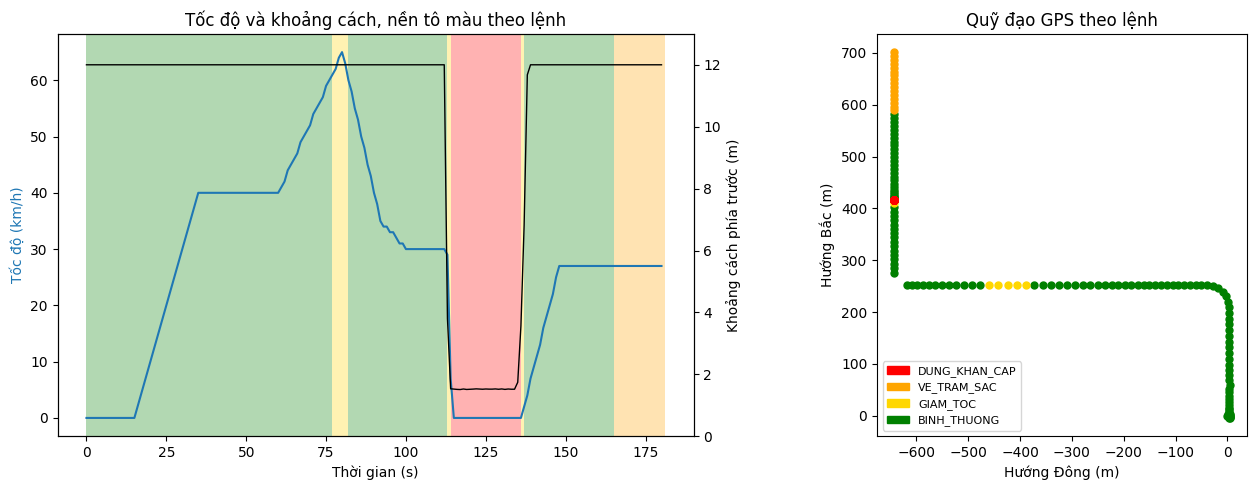

In [581]:
ve_chuyen_xe(quyet_dinh_lai_xe)

### Xem trước: pandas

Đọc file `.csv` rồi thống kê tốc độ bằng thư viện `pandas` chỉ cần vài dòng.

       thoi_gian_s  toc_do_kmh          rpm  muc_pin_pct
count   181.000000  181.000000   181.000000   181.000000
mean     90.000000   26.298343  1725.425414    15.329834
std      52.394338   18.235480   639.338783     0.313749
min       0.000000    0.000000   776.000000    14.900000
25%      45.000000    8.000000  1114.000000    15.100000
50%      90.000000   27.000000  1756.000000    15.200000
75%     135.000000   40.000000  2200.000000    15.600000
max     180.000000   65.000000  3072.000000    15.800000


<Axes: xlabel='thoi_gian_s'>

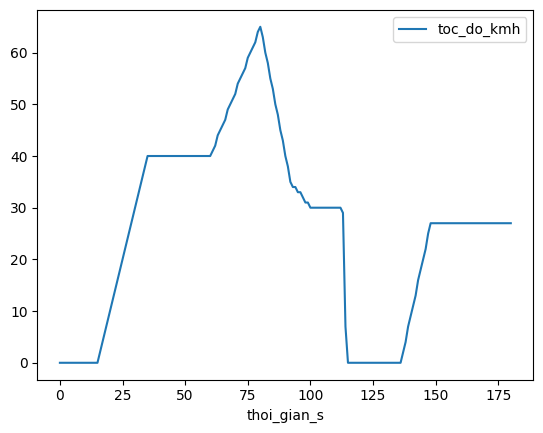

In [582]:
# 💻 Ví dụ: pandas
import pandas as pd

df = pd.read_csv("data/obd.csv")                  # đọc cả file thành một bảng
print(df.describe())                              # thống kê mô tả của từng cột
df.plot(x="thoi_gian_s", y="toc_do_kmh")          # vẽ tốc độ theo thời gian

---
## Tổng kết tuần 1

Chạy ô dưới để kiểm tra toàn bộ bài trong tuần.

In [589]:
ket_qua = [
    kiem_tra_1_1(tb_doc_1, tb_doc_2),
    kiem_tra_1_2(noi_chuoi, tong_so),
    kiem_tra_1_3(thoi_gian_mau, khoang_cach_m),
    kiem_tra_2_1(moi_xe_tra_1, moi_xe_tra_2),
    kiem_tra_2_2(bao_cao),
    kiem_tra_2_3(gio, phut, giay),
    kiem_tra_2_4(vi_do),
    kiem_tra_2_5(gio_vn, phut_vn, giay_vn),
    kiem_tra_3_1(trang_thai),
    kiem_tra_3_2(gioi_han),
    kiem_tra_3_3(trang_thai_fix_1, trang_thai_fix_2, trang_thai_fix_3),
    kiem_tra_4_1(canh_bao_vat_can),
    kiem_tra_4_2(gioi_han_toc_do),
    kiem_tra_4_3(doc_khoang_cach),
    kiem_tra_4_4(nmea_sang_do),
    kiem_tra_5_1(so_mau_hop_le, so_mau_loi),
    kiem_tra_5_2(toc_do_max, toc_do_tb),
    kiem_tra_5_3(t_phanh_gap),
    kiem_tra_5_4(so_giay_rtk_fixed),
    kiem_tra_5_5(quang_duong_phanh),
    kiem_tra_du_an(quyet_dinh_lai_xe),
    kiem_tra_lab(so_lan_dung, so_lan_ve_sac, so_lan_giam_toc, so_lan_binh_thuong, t_dung_dau_tien),
]
import builtins
tong_ket_qua = builtins.sum(ket_qua)
so_ket_qua = builtins.len(ket_qua)

print(f"\nTONG KET TUAN 1: {tong_ket_qua / so_ket_qua} bai dat.")



Bài 1.1 - Trung bình lần đọc cảm biến
  PASS  test 1: tb_doc_1 (cảm biến 1: 8, 9, 10) -> 9.0
  PASS  test 2: tb_doc_2 (cảm biến 2: 7.5, 6, 8) -> 7.166666666666667
  Kết quả: 2/2 — Đạt!

Bài 1.2 - Ép kiểu dữ liệu
  PASS  test 1: noi_chuoi (gia_tri_tho_2 + "5") -> '205'
  PASS  test 2: tong_so (int(gia_tri_tho_2) + 5) -> 25
  Kết quả: 2/2 — Đạt!

Bài 1.3 - Một dòng LiDAR
  PASS  test 1: thoi_gian_mau ("113.00,735.6") -> 113.0
  PASS  test 2: khoang_cach_m (735.6 cm đổi ra mét) -> 7.356
  Kết quả: 2/2 — Đạt!

Bài 2.1 - Chia tiền sạc
  PASS  test 1: moi_xe_tra_1 (300000, phí dv 10%, 3 xe) -> 110000.0
  PASS  test 2: moi_xe_tra_2 (100000, phí dv 15%, 3 xe) -> 38333.33333333333
  Kết quả: 2/2 — Đạt!

Bài 2.2 - Báo cáo quãng đường
  PASS  test 1: bao_cao -> 'Xe đã đi được 60.0 mét trong 3 giây.'
  Kết quả: 1/1 — Đạt!

Bài 2.3 - Đổi giây sang giờ phút giây
  PASS  test 1: gio (5000 giây) -> 1
  PASS  test 2: phut (5000 giây) -> 23
  PASS  test 3: giay (5000 giây) -> 20
  Kết quả: 3/3 — Đạt!



### Lưu bài và nộp bài

Bản mở từ link là bản của repo, không lưu được bài làm. Vào
`File > Save a copy in Drive` ngay từ đầu rồi làm trên bản trong Drive. Đóng tab khi
chưa lưu thì bài làm trong phiên này mất.

Để nộp bài:

1. Tạo repo của bạn từ template tại
   https://github.com/dongthethang2k15kkk/15-weeks-of-military-training/generate
   (chỉ làm một lần, nên chọn Private).
2. Ở bản trong Drive, vào `File > Save a copy in GitHub` (dòng này chỉ có trên bản
   trong Drive), chọn repo của bạn, đường dẫn `week1/week_1.ipynb`, ghi commit
   message dạng `week1: hoan thanh bai tap`.
3. Mở tab Actions của repo: dấu xanh là mọi bài đạt, dấu đỏ là còn bài sai.